In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx

DATA_PATH = "data/facebook_combined.txt"
SEED = 42

In [2]:
edges = np.loadtxt(DATA_PATH, dtype=int)
print(edges.shape)
print(edges[:5])

(88234, 2)
[[0 1]
 [0 2]
 [0 3]
 [0 4]
 [0 5]]


In [3]:
edges = np.sort(edges, axis=1)              # mỗi cạnh: số nhỏ đứng trước
edges = edges[edges[:, 0] != edges[:, 1]]   # bỏ cạnh nối một đỉnh với chính nó
edges = np.unique(edges, axis=0)            # bỏ cạnh trùng

n = edges.max() + 1
m = len(edges)
print(n, m)

4039 88234


In [4]:
G = nx.Graph()
G.add_edges_from(edges)

deg = np.array([d for _, d in G.degree()])
print("Bậc trung bình:", deg.mean())
print("Hệ số phân cụm:", nx.average_clustering(G))
print("Số thành phần liên thông:", nx.number_connected_components(G))

Bậc trung bình: 43.69101262688784
Hệ số phân cụm: 0.6055467186200862
Số thành phần liên thông: 1


Bậc trung vị: 25.0 | Bậc lớn nhất: 1045


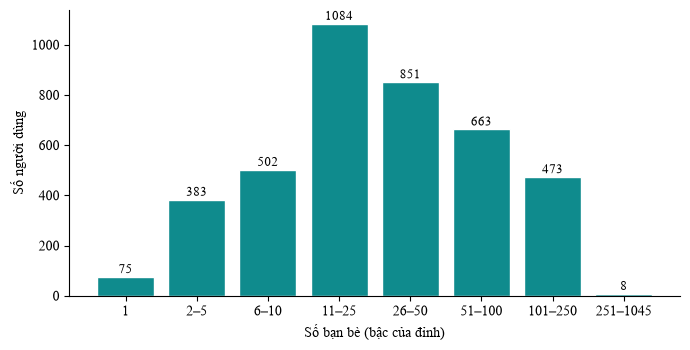

In [5]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Liberation Serif", "DejaVu Serif"]

# Phân phối bậc (số bạn bè) theo nhóm
bins = [(1, 1), (2, 5), (6, 10), (11, 25), (26, 50), (51, 100), (101, 250), (251, deg.max())]
labels = [f"{a}" if a == b else f"{a}–{b}" for a, b in bins]
counts = [int(((deg >= a) & (deg <= b)).sum()) for a, b in bins]
print("Bậc trung vị:", np.median(deg), "| Bậc lớn nhất:", deg.max())

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(labels, counts, color="#0F8B8D", edgecolor="white")
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, c + 15, str(c), ha="center", fontsize=9)
ax.set_xlabel("Số bạn bè (bậc của đỉnh)")
ax.set_ylabel("Số người dùng")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("hinh_phan_phoi_bac.png", dpi=200)
plt.show()

## 2. Chia train/test theo cạnh (giữ cây khung ngẫu nhiên trong train)

In [6]:
from scipy.sparse.csgraph import minimum_spanning_tree

rng = np.random.default_rng(SEED)

# Gán trọng số ngẫu nhiên cho mỗi cạnh -> cây khung nhỏ nhất trở thành cây khung ngẫu nhiên
w = rng.random(m) + 1e-9
W = sp.coo_matrix((w, (edges[:, 0], edges[:, 1])), shape=(n, n)).tocsr()
T = minimum_spanning_tree(W).tocoo()

tree = set(zip(np.minimum(T.row, T.col).tolist(), np.maximum(T.row, T.col).tolist()))
in_tree = np.array([(u, v) in tree for u, v in edges.tolist()])
print("Số cạnh của cây khung:", in_tree.sum())

Số cạnh của cây khung: 4038


In [7]:
TEST_RATIO = 0.20

candidates = np.flatnonzero(~in_tree)              # các cạnh không thuộc cây khung
n_test = int(round(TEST_RATIO * m))
test_idx = rng.choice(candidates, size=n_test, replace=False)

is_test = np.zeros(m, dtype=bool)
is_test[test_idx] = True

train_edges = edges[~is_test]
test_edges = edges[is_test]
print(len(train_edges), len(test_edges))

70587 17647


In [8]:
G_train = nx.Graph()
G_train.add_nodes_from(range(n))
G_train.add_edges_from(train_edges)

print("Thành phần liên thông (train):", nx.number_connected_components(G_train))
print("Bậc nhỏ nhất (train):", min(d for _, d in G_train.degree()))

train_set = set(map(tuple, train_edges))
test_set = set(map(tuple, test_edges))
print("Cạnh trùng giữa train và test:", len(train_set & test_set))

Thành phần liên thông (train): 1
Bậc nhỏ nhất (train): 1
Cạnh trùng giữa train và test: 0


## 3. Personalized PageRank (Chương 11, mục 11.2)

In [9]:
def build_adj(e, n):
    # Ma trận kề đối xứng: A[u, v] = A[v, u] = 1 nếu u và v là bạn
    A = sp.coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(n, n))
    return (A + A.T).tocsr()

A_train = build_adj(train_edges, n)
deg_train = np.asarray(A_train.sum(axis=1)).ravel()

# P[j, i] = 1/bậc(j) nếu j kề i: xác suất đi từ j sang i
P = sp.diags(1.0 / deg_train) @ A_train
print(P.sum(axis=1).min(), P.sum(axis=1).max())

0.9999999999999994 1.0000000000000004


In [10]:
def ppr(q, alpha=0.1, tol=1e-10, max_iter=1000):
    PT = P.T.tocsr()
    e_q = np.zeros(n)
    e_q[q] = 1.0
    pi = e_q.copy()
    for it in range(1, max_iter + 1):
        new = alpha * e_q + (1 - alpha) * (PT @ pi)
        if np.abs(new - pi).sum() < tol:      # dừng khi vector gần như không đổi
            return new, it
        pi = new
    return pi, max_iter

pi, n_iter = ppr(q=0)
print("Số vòng lặp:", n_iter)
print("Tổng xác suất:", pi.sum())
print("Điểm của chính q:", pi[0])

Số vòng lặp: 167
Tổng xác suất: 1.0
Điểm của chính q: 0.1654012846347439


In [11]:
pi_nx = nx.pagerank(G_train, alpha=0.9, personalization={0: 1.0}, tol=1e-12, max_iter=1000)
print("Điểm của chính q (nx):", pi_nx[0])

Điểm của chính q (nx): 0.16540128385818675


In [12]:
# So sánh toàn bộ vector (không chỉ điểm của đỉnh 0)
pi_nx_arr = np.array([pi_nx[i] for i in range(n)])
print("Sai khác lớn nhất trên toàn bộ vector:", np.abs(pi - pi_nx_arr).max())

Sai khác lớn nhất trên toàn bộ vector: 7.765571519158243e-10


## 4. Ba baseline: Common Neighbors, Jaccard, Adamic-Adar

In [13]:
# (A @ A)[x, y] = số đường đi dài 2 từ x đến y = số bạn chung
CN = (A_train @ A_train).toarray()

union = deg_train[:, None] + deg_train[None, :] - CN
JC = np.divide(CN, union, out=np.zeros_like(CN), where=union > 0)

# Đỉnh bậc 1 không thể là bạn chung của hai người khác nhau nên đặt trọng số 0 (log 1 = 0)
w_aa = np.divide(1.0, np.log(deg_train), out=np.zeros(n), where=deg_train > 1)
AA = (A_train @ sp.diags(w_aa) @ A_train).toarray()

print(CN.shape, JC.max(), AA.max())

(4039, 4039) 1.0 293.9875304908463


In [14]:
x, y = 1, 2
nx_, ny_ = set(G_train.neighbors(x)), set(G_train.neighbors(y))
common = nx_ & ny_

print("Common Neighbors:", len(common), "|", CN[x, y])
print("Jaccard:", len(common) / len(nx_ | ny_), "|", JC[x, y])
print("Adamic-Adar:", sum(1 / np.log(G_train.degree(z)) for z in common), "|", AA[x, y])

Common Neighbors: 1 | 1.0
Jaccard: 0.047619047619047616 | 0.047619047619047616
Adamic-Adar: 0.17658608134521075 | 0.17658608134521075


## 5. Đánh giá sơ bộ (tuần 7–10)

### 5.1. PPR cho mọi người dùng cùng lúc
Xếp các vector PPR của mọi người dùng thành cột của ma trận Π: Π = α·I + (1 − α)·Pᵀ·Π, suy ra Π = α·(I − (1 − α)·Pᵀ)⁻¹.
Đồ thị chỉ có 4.039 đỉnh nên nghịch đảo ma trận làm được trong vài giây, nhanh hơn chạy lặp 4.039 lần.

In [15]:
def ppr_all(A, alpha):
    # Trả về S với S[q, i] = điểm PPR của i khi người dùng mục tiêu là q
    d = np.asarray(A.sum(axis=1)).ravel()
    PT = (sp.diags(1.0 / d) @ A).T.toarray()
    Pi = alpha * np.linalg.inv(np.eye(A.shape[0]) - (1 - alpha) * PT)   # cột q là vector PPR của q
    return Pi.T

S_ppr = ppr_all(A_train, 0.1)
print("Sai khác lớn nhất so với lặp luỹ thừa (q = 0):", np.abs(S_ppr[0] - pi).max())

Sai khác lớn nhất so với lặp luỹ thừa (q = 0): 2.501704399193727e-11


### 5.2. Tập kiểm thử và người dùng được đánh giá
Chỉ đánh giá người dùng còn ít nhất 5 bạn trong train và có ít nhất 1 bạn bị ẩn trong test.

In [16]:
A_test = build_adj(test_edges, n)
deg_test = np.asarray(A_test.sum(axis=1)).ravel()

MIN_TRAIN_DEG = 5
eval_users = np.flatnonzero((deg_train >= MIN_TRAIN_DEG) & (deg_test >= 1))
print("Số người dùng được đánh giá:", len(eval_users))
print("Số bạn bị ẩn trung bình mỗi người:", deg_test[eval_users].mean())

Số người dùng được đánh giá: 3373
Số bạn bị ẩn trung bình mỗi người: 10.378298250815298


### 5.3. Hàm đánh giá theo đúng công thức Chương 8 (mục 8.4.1 và 8.4.2)
- Precision(t) = 100 × |S(t) ∩ G| / |S(t)|, Recall(t) = 100 × |S(t) ∩ G| / |G|, với S(t) là Top-10 đề xuất, G là các bạn bị ẩn của người dùng.
- DCG = (1/m) Σ_u Σ_j g_uj / log₂(v_j + 1), với g_uj = 2^rel − 1 = 1 cho bạn bị ẩn (dữ liệu nhị phân); NDCG = DCG / IDCG.
- Loại khỏi danh sách: chính người dùng và những người đã là bạn trong train. Điểm bằng nhau được phá hoà ngẫu nhiên (seed cố định).

In [17]:
K = 10

def evaluate(S, A_tr, A_te, users, k=K, seed=0):
    rng = np.random.default_rng(seed)
    S = S[users].astype(float)
    S += rng.random(S.shape) * 1e-10 * S.max()        # phá hoà, không đổi thứ tự các điểm khác nhau
    S[A_tr[users].toarray() > 0] = -np.inf            # bỏ người đã là bạn
    S[np.arange(len(users)), users] = -np.inf         # bỏ chính người dùng
    top = np.argsort(-S, axis=1)[:, :k]               # Top-k theo điểm giảm dần

    G_te = A_te[users].toarray() > 0
    hits = np.take_along_axis(G_te, top, axis=1).astype(float)
    n_rel = G_te.sum(axis=1)

    precision = 100 * hits.sum(axis=1) / k
    recall = 100 * hits.sum(axis=1) / n_rel
    disc = 1 / np.log2(np.arange(2, k + 2))           # 1 / log2(v + 1), v = 1..k
    dcg = (hits * disc).sum(axis=1)
    idcg = np.array([disc[:min(r, k)].sum() for r in n_rel])
    return {"Precision@10 (%)": precision.mean(), "Recall@10 (%)": recall.mean(), "NDCG@10": dcg.mean() / idcg.mean()}

### 5.4. So sánh PPR (α = 0,1 theo giáo trình) với ba baseline

In [18]:
results = {}
for name, S in [("Common Neighbors", CN), ("Jaccard", JC), ("Adamic-Adar", AA), ("PPR (α = 0,1)", S_ppr)]:
    results[name] = evaluate(S, A_train, A_test, eval_users)
res = pd.DataFrame(results).T
res.round(4)

,Precision@10 (%),Recall@10 (%),NDCG@10
Common Neighbors,37.0442,48.8602,0.5978
Jaccard,35.0519,43.4578,0.5513
Adamic-Adar,37.9692,50.5057,0.6150
"PPR (α = 0,1)",31.4260,41.5493,0.5135


### 5.5. Khảo sát α và chọn α bằng tập validation
Ẩn tiếp 20% số cạnh của đồ thị train (cùng cách giữ cây khung) làm tập validation. α được chọn theo NDCG@10 trên validation,
tập test không tham gia vào việc chọn. Các cột trên test chỉ dùng để phân tích độ nhạy.

In [19]:
def split_edges(e, n, ratio, seed):
    # Giống hệt cách chia ở mục 2, viết thành hàm để dùng lại
    rng = np.random.default_rng(seed)
    w = rng.random(len(e)) + 1e-9
    W = sp.coo_matrix((w, (e[:, 0], e[:, 1])), shape=(n, n)).tocsr()
    T = minimum_spanning_tree(W).tocoo()
    tree = set(zip(np.minimum(T.row, T.col).tolist(), np.maximum(T.row, T.col).tolist()))
    in_tree = np.array([(u, v) in tree for u, v in e.tolist()])
    cand = np.flatnonzero(~in_tree)
    idx = rng.choice(cand, size=int(round(ratio * len(e))), replace=False)
    mask = np.zeros(len(e), dtype=bool); mask[idx] = True
    return e[~mask], e[mask]

tr2, va = split_edges(train_edges, n, 0.20, SEED + 1000)
A_tr2, A_va = build_adj(tr2, n), build_adj(va, n)
d_tr2 = np.asarray(A_tr2.sum(axis=1)).ravel()
d_va = np.asarray(A_va.sum(axis=1)).ravel()
users_va = np.flatnonzero((d_tr2 >= MIN_TRAIN_DEG) & (d_va >= 1))
print("Cạnh train con:", len(tr2), "| Cạnh validation:", len(va), "| Người dùng đánh giá trên validation:", len(users_va))

Cạnh train con: 56470 | Cạnh validation: 14117 | Người dùng đánh giá trên validation: 3232


In [20]:
ALPHAS = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
rows = []
for a in ALPHAS:
    val = evaluate(ppr_all(A_tr2, a), A_tr2, A_va, users_va)["NDCG@10"]
    te = evaluate(ppr_all(A_train, a), A_train, A_test, eval_users)
    rows.append({"α": a, "NDCG@10 (validation)": val, **te})
sweep = pd.DataFrame(rows).set_index("α")
ALPHA_BEST = sweep["NDCG@10 (validation)"].idxmax()
print("α được chọn bằng validation:", ALPHA_BEST)
sweep.round(4)

α được chọn bằng validation: 0.7


,NDCG@10 (validation),Precision@10 (%),Recall@10 (%),NDCG@10
α,,,,
0.05,0.3100,28.7044,36.5401,0.4672
0.10,0.3383,31.4260,41.5493,0.5135
0.15,0.3540,33.1337,44.4357,0.5411
0.20,0.3638,34.3641,46.3004,0.5610
0.30,0.3750,35.8701,48.2740,0.5857
0.40,0.3831,36.8633,49.5141,0.6016
0.50,0.3873,37.5274,50.2309,0.6120
0.60,0.3892,38.0789,50.8959,0.6197
0.70,0.3895,38.5473,51.4545,0.6255


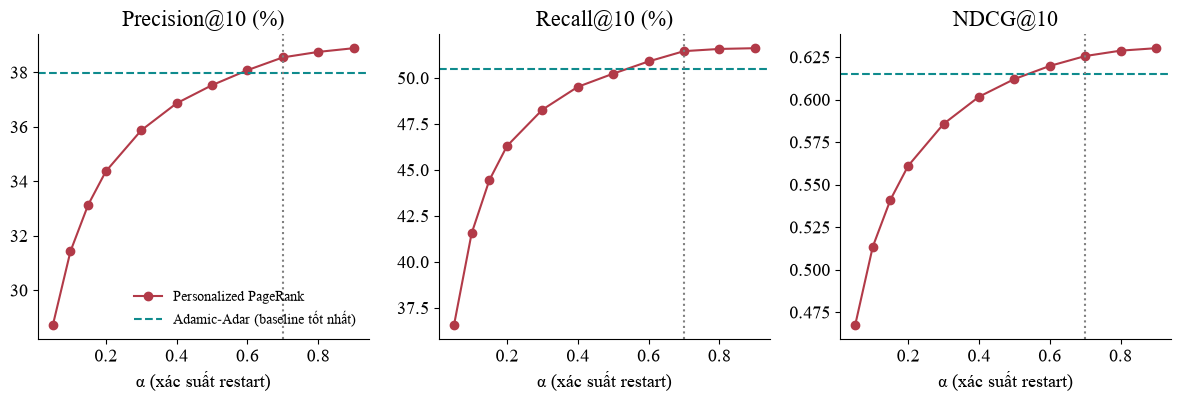

In [21]:
plt.rcParams["font.size"] = 13
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, col in zip(axes, ["Precision@10 (%)", "Recall@10 (%)", "NDCG@10"]):
    ax.plot(sweep.index, sweep[col], marker="o", color="#B23A48", label="Personalized PageRank")
    ax.axhline(res.loc["Adamic-Adar", col], ls="--", color="#0F8B8D", label="Adamic-Adar (baseline tốt nhất)")
    ax.axvline(ALPHA_BEST, ls=":", color="gray")
    ax.set_title(col); ax.set_xlabel("α (xác suất restart)")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].legend(frameon=False, fontsize=10, loc="lower right")
plt.tight_layout()
plt.savefig("hinh_khao_sat_alpha.png", dpi=200)
plt.show()

### 5.6. Bảng so sánh sơ bộ

In [22]:
res.loc[f"PPR (α = {ALPHA_BEST:g}, chọn bằng validation)".replace(".", ",")] = evaluate(ppr_all(A_train, ALPHA_BEST), A_train, A_test, eval_users)
res.round(4).to_csv("ket_qua_so_bo.csv")
sweep.round(4).to_csv("ket_qua_khao_sat_alpha.csv")
res.round(4)

,Precision@10 (%),Recall@10 (%),NDCG@10
Common Neighbors,37.0442,48.8602,0.5978
Jaccard,35.0519,43.4578,0.5513
Adamic-Adar,37.9692,50.5057,0.6150
"PPR (α = 0,1)",31.4260,41.5493,0.5135
"PPR (α = 0,7, chọn bằng validation)",38.5473,51.4545,0.6255
